In [65]:
import random
import numpy as np
import pandas as pd 
import torch
import torchvision
from torchvision import datasets
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import copy 
from sklearn.metrics import confusion_matrix
import time

# Seeding and Data setup 

In [34]:
def set_seed(seed):
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

SPLIT_SEED = 42
RUN_SEEDS = [0, 1, 2]
METRICS = ["train", "val", "clean_test", "shifted_test"]
FIGSIZE = (12, 4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [6]:
train_full = datasets.CIFAR10(root="./data", train=True, download=True)
test_full  = datasets.CIFAR10(root="./data", train=False, download=True)

In [7]:
X_all, y_all = train_full.data, np.array(train_full.targets)

In [8]:
rng = np.random.RandomState(SPLIT_SEED)

In [9]:
train_idx, val_idx = [], []
for c in range(10):
    idx = rng.permutation(np.where(y_all == c)[0])[:50]
    train_idx += idx[:40].tolist()
    val_idx   += idx[40:].tolist()

In [10]:
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val,   y_val   = X_all[val_idx],   y_all[val_idx]
X_clean, y_clean = test_full.data, np.array(test_full.targets)

In [12]:
print(X_train.shape, X_val.shape, X_clean.shape)
print(np.bincount(y_train), np.bincount(y_val))

(400, 32, 32, 3) (100, 32, 32, 3) (10000, 32, 32, 3)
[40 40 40 40 40 40 40 40 40 40] [10 10 10 10 10 10 10 10 10 10]


# Corruption Pipeline 

In [14]:
SHIFT_SEED = 123  # fixed seed for the corruption pipeline

def make_shifted(X, seed=SHIFT_SEED, hidden_fn=None):
    g = np.random.RandomState(seed)
    out = np.empty_like(X)
    for i in range(len(X)):
        img = torch.from_numpy(X[i]).permute(2, 0, 1).float() / 255
        img = TF.rotate(img, angle=g.uniform(-25, 25))
        img = TF.adjust_brightness(img, g.uniform(0.5, 1.5))
        img = TF.adjust_contrast(img, g.uniform(0.5, 1.5))
        top, left = g.randint(0, 17, size=2)
        img[:, top:top+16, left:left+16] = 0
        if hidden_fn is not None:
            img = hidden_fn(img, g)
        out[i] = (img.clamp(0, 1) * 255).byte().permute(1, 2, 0).numpy()
    return out

In [15]:
X_shifted = make_shifted(X_clean)
y_shifted = y_clean
print(X_shifted.shape, X_shifted.dtype)

(10000, 32, 32, 3) uint8


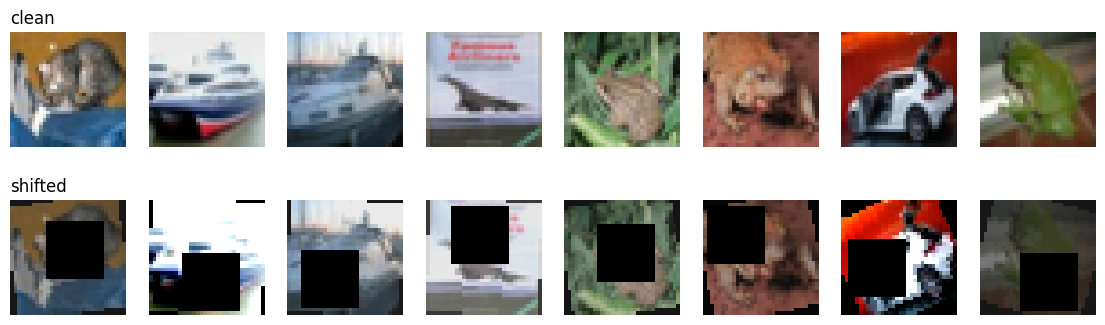

In [18]:
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for j in range(8):
    ax[0, j].imshow(X_clean[j]);   ax[0, j].axis("off")
    ax[1, j].imshow(X_shifted[j]); ax[1, j].axis("off")
ax[0, 0].set_title("clean", loc="left"); ax[1, 0].set_title("shifted", loc="left")
plt.show()

# Normalization, Datasets and DataLoaders

In [20]:
mean = (X_train.mean(axis=(0, 1, 2)) / 255).tolist()
std  = (X_train.std(axis=(0, 1, 2)) / 255).tolist()
norm = T.Normalize(mean, std)

In [21]:
class ImgDS(Dataset):
    def __init__(self, X, y, transform=None):
        self.X = torch.from_numpy(X).permute(0, 3, 1, 2).float() / 255
        self.y = torch.from_numpy(y).long()
        self.transform = transform
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        x = self.X[i]
        if self.transform:
            x = self.transform(x)
        return x, self.y[i]

In [22]:
val_dl     = DataLoader(ImgDS(X_val, y_val, norm), batch_size=100)
clean_dl   = DataLoader(ImgDS(X_clean, y_clean, norm), batch_size=500)
shifted_dl = DataLoader(ImgDS(X_shifted, y_shifted, norm), batch_size=500)

In [23]:
def make_train_dl(train_tf):
    return DataLoader(ImgDS(X_train, y_train, train_tf), batch_size=64, shuffle=True)

In [24]:
xb, yb = next(iter(make_train_dl(norm)))
print(xb.shape, yb.shape, xb.mean().item())

torch.Size([64, 3, 32, 32]) torch.Size([64]) 0.004695826675742865


# Model

In [26]:
def conv_bn(cin, cout, k):
    return nn.Sequential(
        nn.Conv2d(cin, cout, k, padding=k // 2, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True))


In [49]:
class Inception(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = conv_bn(cin, c1, 1)
        self.b3 = nn.Sequential(conv_bn(cin, c3r, 1), conv_bn(c3r, c3, 3))
        self.b5 = nn.Sequential(conv_bn(cin, c5r, 1), conv_bn(c5r, c5, 5))
        self.bp = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1), conv_bn(cin, cp, 1))
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1)

# def build_model(dropout=0.3):
#     return nn.Sequential(
#         conv_bn(3, 32, 3),                       # 32x32x32
#         Inception(32, 16, 16, 24, 8, 12, 12),    # -> 64 channels
#         nn.MaxPool2d(2),                         # 16x16
#         Inception(64, 32, 32, 48, 16, 16, 32),   # -> 128 channels
#         nn.MaxPool2d(2),                         # 8x8
#         nn.AdaptiveAvgPool2d(1), nn.Flatten(),   # 128
#         nn.Dropout(dropout),
#         nn.Linear(128, 10))
def build_model(dropout=0.3):
    return nn.Sequential(
        conv_bn(3, 64, 3),
        Inception(64, 32, 32, 48, 16, 24, 24),     # -> 128 channels
        nn.MaxPool2d(2),
        Inception(128, 64, 64, 96, 24, 48, 48),    # -> 256 channels
        nn.MaxPool2d(2),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        nn.Dropout(dropout),
        nn.Linear(256, 10))

In [50]:
# model = build_model().to(device)
# n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
# print(n_params, model(xb.to(device)).shape)
model = build_model().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert n_params <= 1_000_000
print(n_params)

145242


In [51]:
@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    correct = 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
    return correct / len(dl.dataset)

In [52]:
def train(train_tf, seed, epochs=60, lr=3e-3, wd=5e-4, ls=0.0):
    set_seed(seed)
    model = build_model().to(device)
    dl = make_train_dl(train_tf)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=ls)
    hist = {"train_loss": [], "train_acc": [], "val_acc": []}
    best_val, best_state = -1, None
    for ep in range(epochs):
        model.train()
        tot_loss, correct = 0, 0
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
        sched.step()
        val = evaluate(model, val_dl)
        hist["train_loss"].append(tot_loss / len(dl.dataset))
        hist["train_acc"].append(correct / len(dl.dataset))
        hist["val_acc"].append(val)
        if val > best_val:
            best_val, best_state = val, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, hist

In [53]:
model, hist = train(norm, seed=0)
print(f"train {hist['train_acc'][-1]:.3f} | best val {max(hist['val_acc']):.3f}")

train 0.968 | best val 0.530


# Part A baseline

In [54]:
def run_config(train_tf, ls=0.0):
    rows, hists = [], []
    for s in RUN_SEEDS:
        m, h = train(train_tf, seed=s, ls=ls)
        best = int(np.argmax(h["val_acc"]))
        rows.append([h["train_acc"][best], h["val_acc"][best],
                     evaluate(m, clean_dl), evaluate(m, shifted_dl)])
        hists.append(h)
    return np.array(rows), hists

def summarize(rows):
    names = ["train", "val", "clean_test", "shifted_test"]
    return {k: f"{rows[:, i].mean():.4f} ± {rows[:, i].std():.4f}" for i, k in enumerate(names)}

def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for s, h in zip(RUN_SEEDS, hists):
        ax[0].plot(h["train_loss"], label=f"seed {s}")
        ax[1].plot(h["train_acc"], label=f"train, seed {s}")
        ax[1].plot(h["val_acc"], "--", label=f"val, seed {s}")
    ax[0].set(title=f"{title}: training loss", xlabel="Epoch", ylabel="Loss")
    ax[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy")
    for a in ax: a.legend(); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

{'train': '0.9567 ± 0.0136', 'val': '0.5167 ± 0.0189', 'clean_test': '0.4374 ± 0.0056', 'shifted_test': '0.1840 ± 0.0059'}


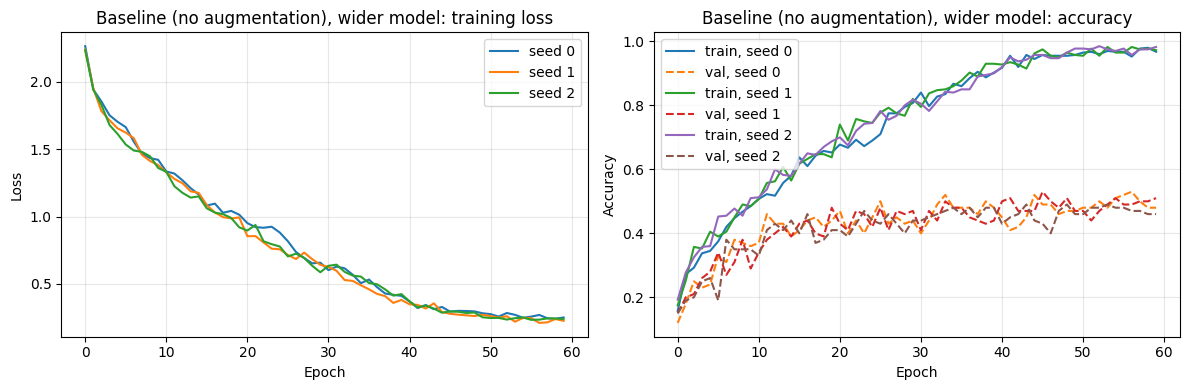

In [55]:
# base_rows, base_hists = run_config(norm)
# print(summarize(base_rows))
# plot_curves(base_hists, "Baseline (no augmentation)")
base_rows, base_hists = run_config(norm)
print(summarize(base_rows))
plot_curves(base_hists, "Baseline (no augmentation), wider model")

# Augmentation pipelines

In [56]:
def add_noise(x):
    return (x + 0.05 * torch.randn_like(x)).clamp(0, 1)

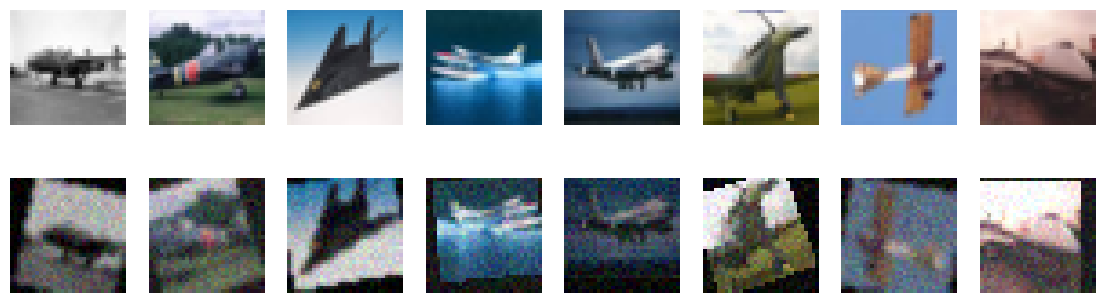

In [57]:
geo   = [T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.RandomRotation(25)]
photo = [T.ColorJitter(0.4, 0.4, 0.4), T.GaussianBlur(3, sigma=(0.1, 1.0)), T.Lambda(add_noise)]
erase = [T.RandomErasing(p=0.5, scale=(0.05, 0.25), value=0)]

tf_geo   = T.Compose(geo + [norm])
tf_photo = T.Compose(photo + [norm])
tf_both  = T.Compose(geo + photo + [norm])
tf_erase = T.Compose(geo + photo + [norm] + erase)

vis = ImgDS(X_train, y_train, T.Compose(geo + photo))
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for j in range(8):
    ax[0, j].imshow(X_train[j]); ax[0, j].axis("off")
    ax[1, j].imshow(vis[j][0].permute(1, 2, 0).clamp(0, 1)); ax[1, j].axis("off")
plt.show()

# Ablation Rows

In [58]:
configs = {
    "Geometric only": tf_geo,
    "Photometric only": tf_photo,
    "Geometric + photometric": tf_both,
    "+ Cutout / Random Erasing": tf_erase,
}
results = {"No augmentation": (base_rows, base_hists)}
for name, tf in configs.items():
    results[name] = run_config(tf)
    print(name, summarize(results[name][0]))

table = pd.DataFrame({n: summarize(r[0]) for n, r in results.items()}).T
table[["val", "clean_test", "shifted_test"]]
print(table.to_markdown())

Geometric only {'train': '0.6700 ± 0.0569', 'val': '0.4500 ± 0.0141', 'clean_test': '0.3727 ± 0.0013', 'shifted_test': '0.2377 ± 0.0083'}
Photometric only {'train': '0.5792 ± 0.0293', 'val': '0.5300 ± 0.0163', 'clean_test': '0.4179 ± 0.0067', 'shifted_test': '0.2240 ± 0.0083'}
Geometric + photometric {'train': '0.3767 ± 0.0042', 'val': '0.3667 ± 0.0125', 'clean_test': '0.3379 ± 0.0097', 'shifted_test': '0.2119 ± 0.0326'}
+ Cutout / Random Erasing {'train': '0.3492 ± 0.0405', 'val': '0.3500 ± 0.0000', 'clean_test': '0.3179 ± 0.0138', 'shifted_test': '0.2331 ± 0.0090'}
|                           | train           | val             | clean_test      | shifted_test    |
|:--------------------------|:----------------|:----------------|:----------------|:----------------|
| No augmentation           | 0.9567 ± 0.0136 | 0.5167 ± 0.0189 | 0.4374 ± 0.0056 | 0.1840 ± 0.0059 |
| Geometric only            | 0.6700 ± 0.0569 | 0.4500 ± 0.0141 | 0.3727 ± 0.0013 | 0.2377 ± 0.0083 |
| Photometric only

### Iteration 1: narrow model (37,658 parameters)

|                           | train           | val             | clean_test      | shifted_test    |
|:--------------------------|:----------------|:----------------|:----------------|:----------------|
| No augmentation           | 0.7875 ± 0.0371 | 0.5300 ± 0.0082 | 0.4224 ± 0.0170 | 0.2011 ± 0.0220 |
| Geometric only            | 0.5550 ± 0.0690 | 0.4067 ± 0.0287 | 0.3618 ± 0.0116 | 0.2349 ± 0.0098 |
| Photometric only          | 0.4800 ± 0.0213 | 0.4533 ± 0.0340 | 0.3903 ± 0.0089 | 0.2294 ± 0.0117 |
| Geometric + photometric   | 0.3842 ± 0.0174 | 0.3433 ± 0.0205 | 0.3327 ± 0.0108 | 0.2068 ± 0.0133 |
| + Cutout / Random Erasing | 0.3325 ± 0.0284 | 0.3500 ± 0.0082 | 0.3131 ± 0.0062 | 0.2358 ± 0.0066 |

Observation: train accuracy fell from 0.7875 (no augmentation) to 0.3325 (with Cutout), so the model underfits under strong augmentation. Next step: widen the model.

### Iteration 2: wider model (145,242 parameters)
|                           | train           | val             | clean_test      | shifted_test    |
|:--------------------------|:----------------|:----------------|:----------------|:----------------|
| No augmentation           | 0.9567 ± 0.0136 | 0.5167 ± 0.0189 | 0.4374 ± 0.0056 | 0.1840 ± 0.0059 |
| Geometric only            | 0.6700 ± 0.0569 | 0.4500 ± 0.0141 | 0.3727 ± 0.0013 | 0.2377 ± 0.0083 |
| Photometric only          | 0.5792 ± 0.0293 | 0.5300 ± 0.0163 | 0.4179 ± 0.0067 | 0.2240 ± 0.0083 |
| Geometric + photometric   | 0.3767 ± 0.0042 | 0.3667 ± 0.0125 | 0.3379 ± 0.0097 | 0.2119 ± 0.0326 |
| + Cutout / Random Erasing | 0.3492 ± 0.0405 | 0.3500 ± 0.0000 | 0.3179 ± 0.0138 | 0.2331 ± 0.0090 |

Observation: the wider model overfits more without augmentation (train 0.9567 vs val 0.5167) and scores the lowest shifted-test accuracy (0.1840). Geometric only (0.2377) and Cutout (0.2331) improve shifted-test accuracy by about 5 points, while geometric + photometric still underfits (train 0.3767). Next step: tune augmentation strength on validation accuracy only.

Notes: train accuracy is measured on augmented batches at the best-validation epoch. Both iterations used Random Erasing after normalization (mean-color fill), and `shifted_test` does not yet include the hidden corruption.

In [59]:
def make_tf(s):
    steps = [T.RandomCrop(32, padding=round(4 * s)),
             T.RandomHorizontalFlip(),
             T.RandomRotation(25 * s),
             T.ColorJitter(0.4 * s, 0.4 * s, 0.4 * s),
             T.Lambda(lambda x: (x + 0.05 * s * torch.randn_like(x)).clamp(0, 1)),
             T.RandomErasing(p=0.5, scale=(0.05, 0.25), value=0)]
    return T.Compose(steps + [norm])

tune = {}
for s in [0.25, 0.5, 0.75]:
    rows, _ = run_config(make_tf(s), ls=0.1)
    tune[s] = rows[:, 1]
    print(f"strength {s}: val {tune[s].mean():.4f} ± {tune[s].std():.4f}")

best_s = max(tune, key=lambda k: tune[k].mean())
print("best strength by val:", best_s)

strength 0.25: val 0.5033 ± 0.0047
strength 0.5: val 0.4367 ± 0.0170
strength 0.75: val 0.3900 ± 0.0294
best strength by val: 0.25


In [60]:
def train(train_tf, seed, epochs=60, lr=3e-3, wd=5e-4, ls=0.0, mix=0.0):
    set_seed(seed)
    model = build_model().to(device)
    dl = make_train_dl(train_tf)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=ls)
    beta = torch.distributions.Beta(mix, mix) if mix > 0 else None
    hist = {"train_loss": [], "train_acc": [], "val_acc": []}
    best_val, best_state = -1, None
    for ep in range(epochs):
        model.train()
        tot_loss, correct = 0, 0
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            if beta is not None:
                lam = beta.sample().item()
                perm = torch.randperm(len(x), device=device)
                out = model(lam * x + (1 - lam) * x[perm])
                loss = lam * loss_fn(out, y) + (1 - lam) * loss_fn(out, y[perm])
            else:
                out = model(x)
                loss = loss_fn(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
        sched.step()
        val = evaluate(model, val_dl)
        hist["train_loss"].append(tot_loss / len(dl.dataset))
        hist["train_acc"].append(correct / len(dl.dataset))
        hist["val_acc"].append(val)
        if val > best_val:
            best_val, best_state = val, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, hist

def run_config(train_tf, ls=0.0, mix=0.0):
    rows, hists = [], []
    for s in RUN_SEEDS:
        m, h = train(train_tf, seed=s, ls=ls, mix=mix)
        best = int(np.argmax(h["val_acc"]))
        rows.append([h["train_acc"][best], h["val_acc"][best],
                     evaluate(m, clean_dl), evaluate(m, shifted_dl)])
        hists.append(h)
    return np.array(rows), hists

In [61]:
mix_rows, mix_hists = run_config(make_tf(best_s), ls=0.1, mix=0.2)
print("Mixup + LS", summarize(mix_rows))

erase_ls_rows, erase_ls_hists = run_config(make_tf(best_s), ls=0.1)
print("Erase + LS", summarize(erase_ls_rows))

Mixup + LS {'train': '0.4533 ± 0.0626', 'val': '0.5133 ± 0.0170', 'clean_test': '0.4248 ± 0.0046', 'shifted_test': '0.2769 ± 0.0073'}
Erase + LS {'train': '0.6692 ± 0.0554', 'val': '0.5033 ± 0.0047', 'clean_test': '0.4155 ± 0.0119', 'shifted_test': '0.2690 ± 0.0034'}


In [71]:
def make_tf(s, geo=True, photo=True, erase=True):
    steps = []
    if geo:
        steps += [T.RandomCrop(32, padding=round(4 * s)), T.RandomHorizontalFlip(), T.RandomRotation(25 * s)]
    if photo:
        steps += [T.ColorJitter(0.4 * s, 0.4 * s, 0.4 * s),
                  T.Lambda(lambda x: (x + 0.05 * s * torch.randn_like(x)).clamp(0, 1))]
    if erase:
        steps.append(T.RandomErasing(p=0.5, scale=(0.05, 0.25), value=0))
    return T.Compose(steps + [norm])

final_results = {"No augmentation": base_rows}
final_results["Geometric only"]            = run_config(make_tf(best_s, photo=False, erase=False))[0]
final_results["Photometric only"]          = run_config(make_tf(best_s, geo=False, erase=False))[0]
final_results["Geometric + photometric"]   = run_config(make_tf(best_s, erase=False))[0]
final_results["+ Cutout / Random Erasing"] = run_config(make_tf(best_s))[0]
final_results["+ Mixup + label smoothing"] = mix_rows
final_results["Final model"]               = mix_rows

final_table = pd.DataFrame({n: summarize(r) for n, r in final_results.items()}).T
print(final_table[["val", "clean_test", "shifted_test"]].to_markdown())

|                           | val             | clean_test      | shifted_test    |
|:--------------------------|:----------------|:----------------|:----------------|
| No augmentation           | 0.5167 ± 0.0189 | 0.4374 ± 0.0056 | 0.1840 ± 0.0059 |
| Geometric only            | 0.5300 ± 0.0082 | 0.4258 ± 0.0097 | 0.2308 ± 0.0076 |
| Photometric only          | 0.5367 ± 0.0047 | 0.4416 ± 0.0133 | 0.2010 ± 0.0317 |
| Geometric + photometric   | 0.5100 ± 0.0082 | 0.4206 ± 0.0013 | 0.2499 ± 0.0069 |
| + Cutout / Random Erasing | 0.5000 ± 0.0163 | 0.4057 ± 0.0129 | 0.2662 ± 0.0077 |
| + Mixup + label smoothing | 0.5133 ± 0.0170 | 0.4248 ± 0.0046 | 0.2769 ± 0.0073 |
| Final model               | 0.5133 ± 0.0170 | 0.4248 ± 0.0046 | 0.2769 ± 0.0073 |


# Final Models

In [62]:
final_model, final_hist = train(make_tf(best_s), seed=RUN_SEEDS[0], ls=0.1, mix=0.2)
classes = train_full.classes


In [63]:
@torch.no_grad()
def predict(model, dl):
    model.eval()
    return torch.cat([model(x.to(device)).argmax(1).cpu() for x, _ in dl]).numpy()

airplane: 0.438
automobile: 0.338
bird: 0.378
cat: 0.335
deer: 0.171
dog: 0.117
frog: 0.462
horse: 0.169
ship: 0.257
truck: 0.208


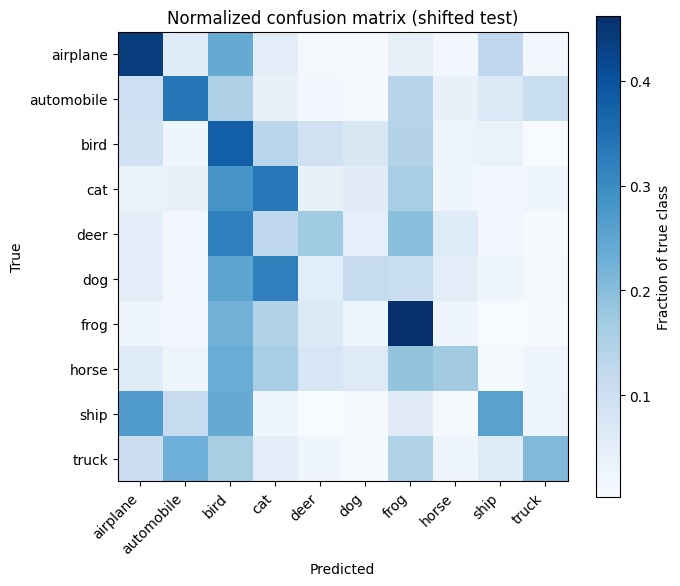

In [66]:
p = predict(final_model, shifted_dl)
cm = confusion_matrix(y_shifted, p, normalize="true")

for c, a in zip(classes, cm.diagonal()):
    print(f"{c}: {a:.3f}")

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues"); plt.colorbar(label="Fraction of true class")
plt.xticks(range(len(classes)), classes, rotation=45, ha="right")
plt.yticks(range(len(classes)), classes)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Normalized confusion matrix (shifted test)")
plt.tight_layout(); plt.show()

dog -> cat: 0.322
deer -> bird: 0.319
cat -> bird: 0.284
ship -> airplane: 0.268
dog -> bird: 0.249


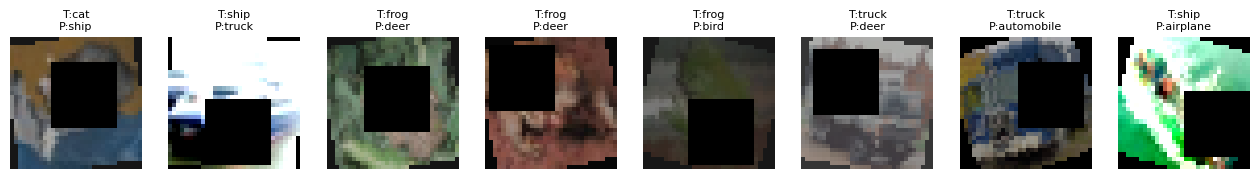

In [67]:
off = cm.copy(); np.fill_diagonal(off, 0)
for k in np.argsort(off.ravel())[::-1][:5]:
    i, j = np.unravel_index(k, off.shape)
    print(f"{classes[i]} -> {classes[j]}: {off[i, j]:.3f}")

wrong = np.where(p != y_shifted)[0][:8]
fig, ax = plt.subplots(1, 8, figsize=(16, 2.5))
for a, k in zip(ax, wrong):
    a.imshow(X_shifted[k]); a.axis("off")
    a.set_title(f"T:{classes[y_shifted[k]]}\nP:{classes[p[k]]}", fontsize=8)
plt.show()

In [68]:
tta_tf = T.Compose([T.RandomHorizontalFlip(), T.RandomCrop(32, padding=2)])
X_s = torch.from_numpy(X_shifted).permute(0, 3, 1, 2).float() / 255
y_s = torch.from_numpy(y_shifted)

In [69]:
@torch.no_grad()
def acc_tta(model, n):
    set_seed(RUN_SEEDS[0])
    model.eval()
    t0 = time.time()
    probs = torch.zeros(len(X_s), len(classes))
    for _ in range(n):
        for i in range(0, len(X_s), 500):
            batch = torch.stack([tta_tf(x) for x in X_s[i:i+500]])
            probs[i:i+500] += model(norm(batch).to(device)).softmax(1).cpu()
    return (probs.argmax(1) == y_s).float().mean().item(), time.time() - t0

In [70]:
t0 = time.time(); plain_acc = evaluate(final_model, shifted_dl); plain_t = time.time() - t0
tta_acc, tta_t = acc_tta(final_model, 8)
print(f"no TTA: {plain_acc:.4f} in {plain_t:.2f}s | TTA x8: {tta_acc:.4f} in {tta_t:.2f}s")

no TTA: 0.2873 in 1.48s | TTA x8: 0.2898 in 13.81s


In [72]:
def hidden_fn(img, g):
    if g.rand() < 0.5:                                   # ASSUMPTION: random grayscale, p = 0.5
        img = TF.rgb_to_grayscale(img, num_output_channels=3)
    return img

def apply_hidden_only(X, hidden_fn, seed=SHIFT_SEED):
    g = np.random.RandomState(seed)
    out = np.empty_like(X)
    for i in range(len(X)):
        img = torch.from_numpy(X[i]).permute(2, 0, 1).float() / 255
        img = hidden_fn(img, g)
        out[i] = (img.clamp(0, 1) * 255).byte().permute(1, 2, 0).numpy()
    return out

In [73]:

X_hidden = apply_hidden_only(X_clean, hidden_fn)
hidden_dl = DataLoader(ImgDS(X_hidden, y_clean, norm), batch_size=500)

base_model, _ = train(norm, seed=RUN_SEEDS[0])           # baseline, seed 0, for comparison
for name, m in [("Baseline", base_model), ("Final", final_model)]:
    print(f"{name}: clean {evaluate(m, clean_dl):.4f} | hidden-only {evaluate(m, hidden_dl):.4f}")

Baseline: clean 0.4453 | hidden-only 0.4242
Final: clean 0.4228 | hidden-only 0.3858


## Part A: Baseline diagnosis
Baseline: train 0.9567, val 0.5167, clean test 0.4374, shifted test 0.1840. The large train-to-clean gap shows **overfitting**, and the further clean-to-shifted drop shows **covariate shift**. The failure is both.

## Part B
1. **Vertical flip:** expected to hurt (not tested). Objects are upright in CIFAR-10 and the test set has no vertical flips, so flipped images are out-of-distribution.
2. **±90° rotation vs ±25° test:** it covers the test range but wastes capacity on orientations never seen at test time and makes the task harder. In our runs, stronger augmentation lowered val accuracy (0.5033 at strength 0.25, 0.4367 at 0.5, 0.3900 at 0.75).
3. **Too much augmentation:** a small model underfits. Training accuracy fell from 0.9567 to 0.3492 (wider model) when augmentations were stacked at full strength.

## Part C
- **BatchNorm** after every convolution: stabilizes training.
- **Dropout (0.3)** after global average pooling, before the classifier: features are dense there, while neighboring pixels in early conv layers are highly correlated.
- **Weight decay (AdamW, 5e-4)**, **cosine LR schedule**, and a **best-validation checkpoint** (validation-based early stopping).
- **Label smoothing (0.1)** and **Mixup (alpha 0.2)** in the final model.
These were fixed by design and not ablated individually. Only augmentation strength was tuned (3 values, val only).

## Part D
Shifted-test accuracy rose from 0.1840 to 0.2769. The largest single step was **geometric augmentation** (+0.0468), matching the test's rotation. Random Erasing (+0.0163) matches the occlusion box. Mixup + label smoothing added +0.0107, which is weak evidence and not separable. Clean-test accuracy fell only from 0.4374 to 0.4248.

## Part E
Best classes (shifted test, seed 0): frog 0.462, airplane 0.438. Worst: dog 0.117, horse 0.169, deer 0.171. Top confusions: dog→cat 0.322, deer→bird 0.319, cat→bird 0.284, ship→airplane 0.268. Similar-looking animals mix, and ship/airplane share blue backgrounds.
In all eight sampled failures, the black box covers the center of the object; several are also rotated or washed out, leaving only color and background cues.

## Part F
TTA (8 copies, seed 0): 0.2873 → 0.2898 (+0.0025), inference 1.48 s → 13.81 s (about 9.3×). The gain is below the seed std (0.0073), so it is inconclusive.

### Notes and limitations
- Seeds: SPLIT_SEED = 42, SHIFT_SEED = 123, RUN_SEEDS = [0, 1, 2]. Tables report mean ± std (population std) over 3 seeds; Parts E, F and E4 use seed 0.
- The official hidden corruption was not provided. `shifted_test` uses only the listed corruptions, and E4 uses an **assumed** corruption (random grayscale, p = 0.5).
- Hyperparameters were chosen on the clean 100-image val split, which favors weak augmentation (final rotation ±6.25°).
- The model was widened after seeing Iteration 1 results (training accuracy had collapsed; test columns were visible).

## Part E4: hidden-corruption test (ASSUMED: random grayscale, p = 0.5; seed 0)

| Model | Clean test | Hidden-only | Drop |
|---|---|---|---|
| Baseline | 0.4453 | 0.4242 | 0.0211 |
| Final model | 0.4228 | 0.3858 | 0.0370 |

The augmentation did **not** generalize to this corruption: the final model lost more accuracy than the baseline. The pipeline has only mild color jitter and no grayscale or channel augmentation. This is one seed with an assumed corruption, and the difference is close to the seed std, so it is suggestive and not conclusive. An untested fix is adding `T.RandomGrayscale` to training.